<div dir="rtl">

# הרצאה 3: גדילת הפרעות, אורך ג'ינס והרשת הקוסמית

**מה במחברת.** פותרים את משוואת הגדילה הליניארית ב-$\Lambda$CDM, מחשבים את קצב הגדילה $f=d\ln D/d\ln a$ ואת $f\sigma_8(z)$, ובודקים נומרית את אפקט מסזרוש ואת אורך ג'ינס.

**משוואת הגדילה** (תת-אופק, חומר לא-יחסותי):
$$\ddot\delta+2H\dot\delta-4\pi G\bar\rho_m\delta=0
\quad\Longrightarrow\quad
\delta''+\Big(2+\frac{d\ln H}{d\ln a}\Big)\delta'-\frac32\Omega_m(a)\,\delta=0,$$
כאשר $'=d/d\ln a$.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
c = 299792.458            # km/s

h, Om0 = 0.674, 0.315
OL0 = 1 - Om0
sigma8_0 = 0.811                     # Planck 2018

def growth(Om=Om0, OL=OL0, a_i=1e-3, a_eval=None):
    # returns a, D(a) normalised to D=a deep in matter era, and f = dlnD/dlna
    Ok = 1 - Om - OL
    def rhs(lna, y):
        a = np.exp(lna)
        E2 = Om/a**3 + Ok/a**2 + OL
        dlnH = (-3*Om/a**3 - 2*Ok/a**2)/(2*E2)
        Oma = Om/a**3/E2
        return [y[1], -(2 + dlnH)*y[1] + 1.5*Oma*y[0]]
    if a_eval is None: a_eval = np.logspace(np.log10(a_i), 0, 400)
    s = solve_ivp(rhs, [np.log(a_i), 0], [a_i, a_i], t_eval=np.log(a_eval), rtol=1e-10, atol=1e-14)
    a = np.exp(s.t); D, dD = s.y
    return a, D, dD/D

<div dir="rtl">

## 1. פקטור הגדילה $D(a)$ בשלושה יקומים
ב-EdS ‏$D\propto a$ לאורך כל הדרך. כשהאנרגיה האפלה או העקמומיות משתלטות, הגדילה נבלמת.

</div>

$\Lambda$CDM      : D(a=1) = 0.7878  (EdS would give 1),  f(z=0) = 0.527
open (0.315, 0)   : D(a=1) = 0.4741  (EdS would give 1),  f(z=0) = 0.507
EdS               : D(a=1) = 1.0000  (EdS would give 1),  f(z=0) = 1.000


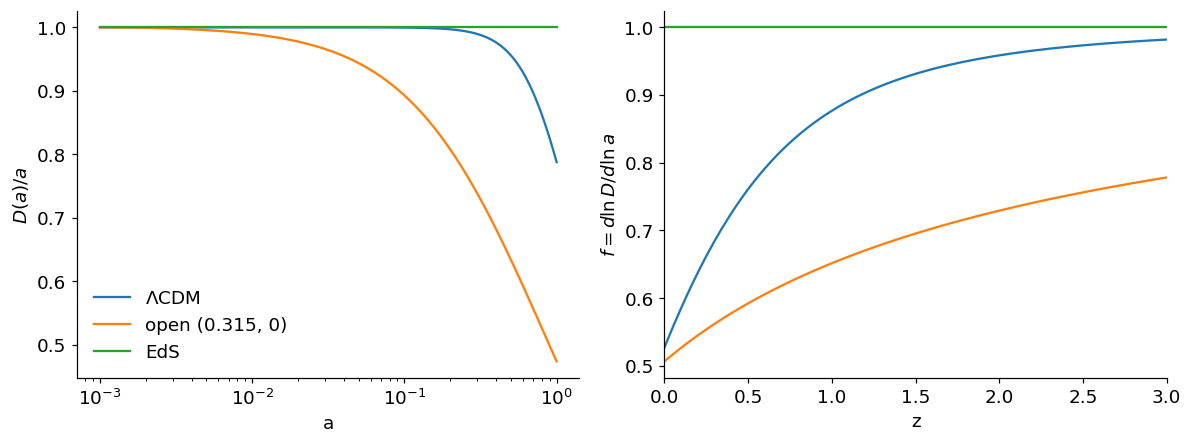

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for i, (lab, Om, OL) in enumerate([(r"$\Lambda$CDM", Om0, OL0), ("open (0.315, 0)", Om0, 0.0), ("EdS", 1.0, 0.0)]):
    a, D, f = growth(Om, OL)
    ax[0].plot(a, D/a, f"C{i}", label=lab)
    ax[1].plot(1/a - 1, f, f"C{i}", label=lab)
    print(f"{lab:18s}: D(a=1) = {D[-1]:.4f}  (EdS would give 1),  f(z=0) = {f[-1]:.3f}")
ax[0].set_xscale("log"); ax[0].set_xlabel("a"); ax[0].set_ylabel(r"$D(a)/a$"); ax[0].legend(frameon=False)
ax[1].set_xlim(0, 3); ax[1].set_xlabel("z"); ax[1].set_ylabel(r"$f=d\ln D/d\ln a$")
fig.tight_layout(); plt.show()

<div dir="rtl">

## 2. האינדקס $\gamma$: ‏$f\simeq\Omega_m(a)^\gamma$
ב-GR עם $\Lambda$ מקבלים $\gamma\approx0.55$. תיאוריות כבידה שונות נותנות $\gamma$ אחר, ולכן $f\sigma_8$ ממדידות RSD בודק את GR.

</div>

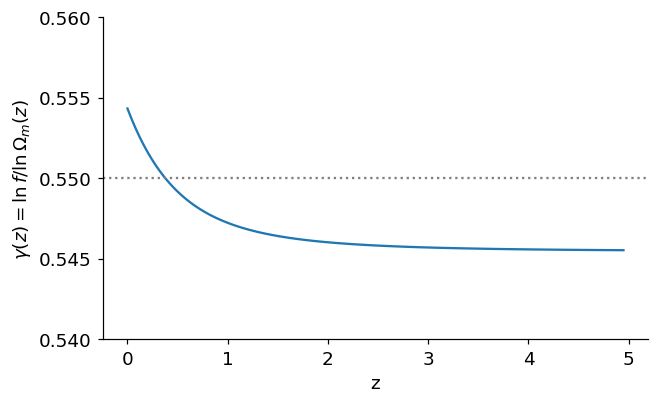

gamma(z=0) = 0.5543


In [3]:
a, D, f = growth()
Oma = Om0/a**3/(Om0/a**3 + OL0)
gam = np.log(f)/np.log(Oma)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
m = (1/a - 1) < 5
ax.plot(1/a[m] - 1, gam[m], "C0"); ax.axhline(0.55, color="gray", ls=":")
ax.set_xlabel("z"); ax.set_ylabel(r"$\gamma(z)=\ln f/\ln\Omega_m(z)$"); ax.set_ylim(0.54, 0.56); plt.show()
print(f"gamma(z=0) = {gam[-1]:.4f}")

<div dir="rtl">

## 3. תחזית $f\sigma_8(z)$
$\sigma_8(z)=\sigma_8\,D(z)/D(0)$, ולכן $f\sigma_8(z)=f(z)\,\sigma_8\,D(z)/D(0)$. להלן שלושה ערכי $\Omega_m$ (עם $\sigma_8$ קבוע היום), יחד עם כמה מדידות RSD מייצגות.

</div>

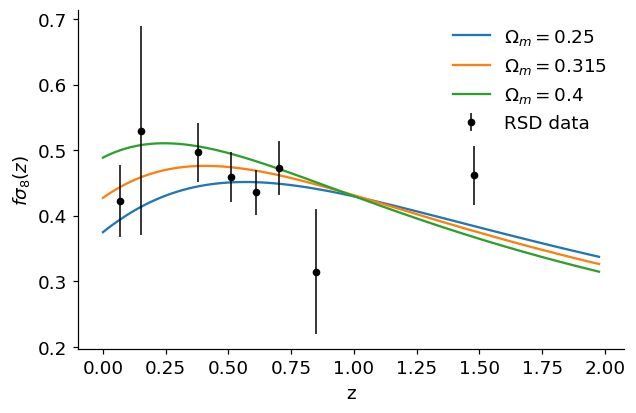

In [4]:
# representative RSD points (z, f sigma8, err): 6dFGS, SDSS MGS, BOSS DR12 (3 bins), eBOSS LRG, ELG, QSO
rsd = np.array([[0.067, 0.423, 0.055], [0.15, 0.53, 0.16], [0.38, 0.497, 0.045], [0.51, 0.459, 0.038],
                [0.61, 0.436, 0.034], [0.70, 0.473, 0.041], [0.85, 0.315, 0.095], [1.48, 0.462, 0.045]])
fig, ax = plt.subplots(figsize=(6.4, 4))
for i, Om in enumerate([0.25, Om0, 0.40]):
    a, D, f = growth(Om, 1 - Om)
    z = 1/a - 1; m = z < 2
    ax.plot(z[m], (f*sigma8_0*D/D[-1])[m], f"C{i}", label=rf"$\Omega_m={Om}$")
ax.errorbar(*rsd.T, fmt="o", color="k", ms=4, lw=1, label="RSD data")
ax.set_xlabel("z"); ax.set_ylabel(r"$f\sigma_8(z)$"); ax.legend(frameon=False); plt.show()

<div dir="rtl">

המדידות: Beutler+ 2012, MNRAS 423, 3430; Howlett+ 2015, MNRAS 449, 848; Alam+ 2017, MNRAS 470, 2617; eBOSS: Alam+ 2021, PRD 103, 083533.

</div>

<div dir="rtl">

## 4. אורך ג'ינס
להפרעה בגז עם מהירות קול $c_s$:
$\ddot\delta_k+2H\dot\delta_k=\big(4\pi G\bar\rho-c_s^2k^2/a^2\big)\delta_k$. מתחת לאורך ג'ינס ($k>k_J$) ההפרעה מתנודדת ולא גדלה. ב-EdS עם יחס $q=k/k_J$ קבוע:
$\delta''+\tfrac12\delta'-\tfrac32(1-q^2)\delta=0$.

</div>

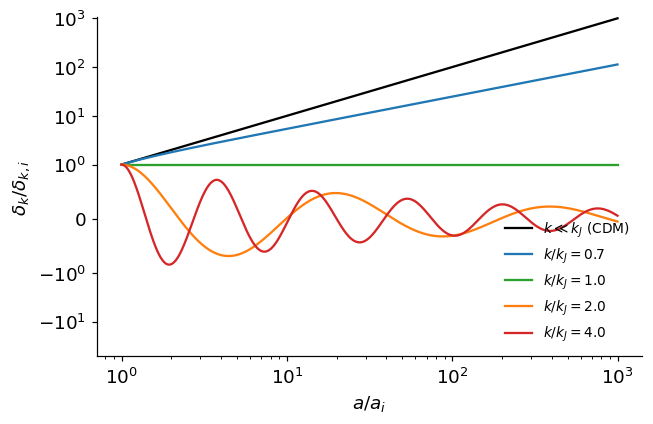

In [5]:
def rhs_j(lna, y, q):
    d, dp = y
    return [dp, -0.5*dp + 1.5*(1 - q**2)*d]

fig, ax = plt.subplots(figsize=(6.4, 4))
lna = np.linspace(0, np.log(1000), 600)
for q, col in [(0.0, "k"), (0.7, "C0"), (1.0, "C2"), (2.0, "C1"), (4.0, "C3")]:
    s = solve_ivp(rhs_j, (0, lna[-1]), [1.0, 1.0 if q < 1 else 0.0], t_eval=lna, args=(q,), rtol=1e-8)
    ax.plot(np.exp(s.t), s.y[0], color=col, label=r"$k\ll k_J$ (CDM)" if q == 0 else rf"$k/k_J={q}$")
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel(r"$a/a_i$"); ax.set_ylabel(r"$\delta_k/\delta_{k,i}$"); ax.legend(frameon=False, fontsize=9); plt.show()

<div dir="rtl">

---
# תרגילים פתורים נוספים

### תרגיל א: כמה גדלו ההפרעות מאז ה-CMB?
ב-$z=1090$ האנאיזוטרופיות הן $\delta T/T\sim10^{-5}$, ולכן $\delta_b\sim10^{-5}$-$10^{-4}$. פי כמה גדלה הפרעה ליניארית מאז, ב-EdS וב-$\Lambda$CDM? האם בריונים לבד יכולים ליצור גלקסיות עד היום?

**פתרון.** ב-EdS הגדילה היא $1+z=1091$. ב-$\Lambda$CDM ההאטה המאוחרת מורידה אותה ל-$\approx0.79\times1091$. $10^{-4}\times860\sim0.1\ll1$: בלי חומר אפל שהתחיל לגדול לפני הרקומבינציה, אין מבנים לא-ליניאריים היום.

</div>

In [6]:
a, D, f = growth(a_i=1e-4)
a_star = 1/1091
D_star = np.interp(a_star, a, D)
print(f"LCDM growth since z=1090: D(1)/D(a*) = {D[-1]/D_star:.0f}   (EdS: {1/a_star:.0f})")
print(f"suppression by Lambda: g0 = D(1)/a = {D[-1]/1:.3f}  (normalised so that D=a early)")

LCDM growth since z=1090: D(1)/D(a*) = 860   (EdS: 1091)
suppression by Lambda: g0 = D(1)/a = 0.788  (normalised so that D=a early)


<div dir="rtl">

### תרגיל ב: אפקט מסזרוש
בעידן הקרינה ההפרעות בחומר אפל כמעט לא גדלות. עם $y=a/a_{\rm eq}$ המשוואה היא
$\frac{d^2\delta}{dy^2}+\frac{2+3y}{2y(1+y)}\frac{d\delta}{dy}-\frac{3}{2y(1+y)}\delta=0$, והפתרון הגדל הוא $\delta\propto1+\tfrac32y$.
בדקו נומרית, וחשבו את הגדילה בין $z=10^5$ לשוויון.

</div>

In [7]:
def mesz(y, u):
    d, dd = u
    return [dd, -(2 + 3*y)/(2*y*(1 + y))*dd + 1.5/(y*(1 + y))*d]
y0 = 1e-3
s = solve_ivp(mesz, [y0, 10], [1 + 1.5*y0, 1.5], dense_output=True, rtol=1e-10)
yy = np.array([0.01, 0.1, 1, 10])
print("numeric / (1 + 3y/2):", np.round(s.sol(yy)[0]/(1 + 1.5*yy), 6))
aeq = 1/3400; yi = (1/1e5)/aeq
print(f"growth z=1e5 -> z_eq: {2.5/(1 + 1.5*yi):.2f}   while a grew by {1/yi:.0f}")

numeric / (1 + 3y/2): [1. 1. 1. 1.]
growth z=1e5 -> z_eq: 2.38   while a grew by 29


<div dir="rtl">

**מסקנה.** ההפרעה גדלה פי 2.4 בלבד בזמן שהיקום גדל פי 30. זה מה שיוצר את השבירה (turnover) בספקטרום ההספק ב-$k_{\rm eq}\approx0.01\,h/$Mpc.

### תרגיל ג: מתי נוצרה ההילה הראשונה של $\sigma=3$?
הילה נוצרת כש-$\delta_L$ מגיע ל-$\delta_c=1.686$. שיא בגובה $\nu\sigma(M)$ קורס כאשר $\nu\,\sigma(M)\,D(z)/D(0)=1.686$. מצאו את הסחת הקריסה עבור $\sigma(M)=1,2,3$ ו-$\nu=1,3$.

</div>

In [8]:
a, D, f = growth()
# a peak of height nu*sigma(M) collapses when nu*sigma(M)*D(z)/D(0) = 1.686
for sigM in (1.0, 2.0, 3.0):          # rms linear overdensity today on the scale M
    for nu in (1, 3):
        g = 1.686/(nu*sigM)            # required D(z)/D(0)
        if g >= 1:
            print(f"sigma(M)={sigM}, {nu}-sigma peak: not collapsed yet (needs D/D0 = {g:.2f})")
        else:
            print(f"sigma(M)={sigM}, {nu}-sigma peak: collapses at z = {1/np.interp(g, D/D[-1], a) - 1:.2f}")

sigma(M)=1.0, 1-sigma peak: not collapsed yet (needs D/D0 = 1.69)
sigma(M)=1.0, 3-sigma peak: collapses at z = 1.18
sigma(M)=2.0, 1-sigma peak: collapses at z = 0.32
sigma(M)=2.0, 3-sigma peak: collapses at z = 3.50
sigma(M)=3.0, 1-sigma peak: collapses at z = 1.18
sigma(M)=3.0, 3-sigma peak: collapses at z = 5.77


<div dir="rtl">

**מסקנה.** בסקאלות קטנות ($\sigma(M)=3$, בערך $10^{8}$-$10^{9}\,M_\odot$) שיא של $3\sigma$ קורס כבר ב-$z\approx6$ בקירוב זה, ושיאים נדירים יותר עוד קודם. זה ה-"bottom-up": מבנים קטנים נוצרים ראשונים.

</div>